In [2]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

## Setup
$80\%$ of the data is used for training (the functions $f_i$); the other $20\%$ is held out and not used.

Preprocessing (**log + clip**):
1. take the logarithm of the skewed features `AveRooms`, `AveBedrms`, `Population`, `AveOccup`;
2. standardize with the mean and the standard deviation of the training set;
3. clip every standardized feature to $[-3, 3]$;
4. add the constant feature $1$ (bias).

Without steps 1 and 3 a few districts with extreme features give $L_{\max} \approx 12900$ while $\bar L = 9$,
and the stepsize $\frac{1}{A} = \frac{1}{2L_{\max}}$ of the theory is useless (see the table below).

In [3]:
TEST_SIZE = 0.2
SEED = 0          # SGD randomness
SPLIT_SEED = 2    # train/test partition
LOG_FEATURES = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
CLIP = 3.0

data = fetch_california_housing()
FEATURES = data.feature_names + ["bias"]
raw_train, raw_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=TEST_SIZE, random_state=SPLIT_SEED)


def make_features(raw_train, raw_test, log=True, clip=CLIP):
    # log of the skewed features, standardize with the train statistics, clip, add bias
    log_idx = [data.feature_names.index(name) for name in LOG_FEATURES]

    def transform(R):
        R = R.copy()
        if log:
            R[:, log_idx] = np.log(R[:, log_idx])
        return R

    T_train, T_test = transform(raw_train), transform(raw_test)
    mean, std = T_train.mean(axis=0), T_train.std(axis=0)
    out = []
    for T in (T_train, T_test):
        Z = (T - mean) / std
        if clip is not None:
            Z = np.clip(Z, -clip, clip)
        out.append(np.hstack([Z, np.ones((len(Z), 1))]))
    return out


X_train, X_test = make_features(raw_train, raw_test)
N, D = X_train.shape
print(f"n = {N} training points (held out: {len(X_test)}), d = {D}")

n = 16512 training points (held out: 4128), d = 9


## The functions
`i` can be one index or an array of indices, and `w` one point of shape `(d,)` or a batch of shape `(..., d)`
(e.g. one point per independent SGD run).

In [4]:
def f_i(X, y, i, w):
    # f_i(w) = 1/2 (<x_i, w> - y_i)^2
    return 0.5 * (np.einsum("...j,...j->...", X[i], w) - y[i]) ** 2


def grad_f_i(X, y, i, w):
    # grad f_i(w) = x_i (<x_i, w> - y_i)
    r = np.einsum("...j,...j->...", X[i], w) - y[i]
    return X[i] * r[..., None]


def f(X, y, w):
    # f(w) = 1/n sum_i f_i(w) = 1/(2n) ||Phi w - y||^2
    return 0.5 * np.mean((w @ X.T - y) ** 2, axis=-1)


def grad_f(X, y, w):
    # grad f(w) = 1/n Phi^T (Phi w - y)
    return (w @ X.T - y) @ X / len(y)

## Constants of the problem

In [5]:
def constants(X, y):
    n = len(y)
    w_star = np.linalg.solve(X.T @ X, X.T @ y)
    L_i = np.sum(X ** 2, axis=1)                            # ||x_i||^2
    eig = np.linalg.eigvalsh(X.T @ X / n)
    G = grad_f_i(X, y, np.arange(n), w_star)                # rows: grad f_i(w*)
    sigma2 = np.mean(np.sum(G ** 2, axis=1))                # sigma_*^2
    return dict(w_star=w_star, f_star=f(X, y, w_star), L_i=L_i, L_max=L_i.max(), L_bar=L_i.mean(),
                L=eig[-1], mu=eig[0], A=2 * L_i.max(), C=2 * sigma2, sigma2=sigma2)

Effect of the preprocessing (same split, same model):

In [6]:
print(f"{'features':12s} {'mu':>7s} {'L':>6s} {'L_bar':>6s} {'L_max':>8s} {'A':>8s} {'C':>7s}")
for name, log, clip in [("raw", False, None), ("log", True, None), ("clip", False, CLIP), ("log + clip", True, CLIP)]:
    tr, _ = make_features(raw_train, raw_test, log=log, clip=clip)
    k = constants(tr, y_train)
    print(f"{name:12s} {k['mu']:7.4f} {k['L']:6.3f} {k['L_bar']:6.2f} {k['L_max']:8.1f} {k['A']:8.1f} "
          f"{k['C']:7.3f}")

features          mu      L  L_bar    L_max        A       C
raw           0.0459  2.026   9.00  12913.5  25827.0  49.427
log           0.0512  2.091   9.00    624.9   1249.8  13.807
clip          0.0102  1.957   6.05     36.3     72.5   6.062
log + clip    0.0484  2.034   7.89     45.3     90.7   7.954


The problem we use from now on (log + clip):

In [7]:
c = constants(X_train, y_train)
w_star, f_star, mu, L, A, C = c["w_star"], c["f_star"], c["mu"], c["L"], c["A"], c["C"]
print(f"mu = {mu:.4f}, L = {L:.4f}, L_bar = {c['L_bar']:.2f}, L_max = {c['L_max']:.2f}")
print(f"A = {A:.2f}, C = {C:.3f}, f* = {f_star:.4f}")
print(f"||grad f(w*)|| = {np.linalg.norm(grad_f(X_train, y_train, w_star)):.1e}")
print("w* =", ", ".join(f"{name} {v:+.4f}" for name, v in zip(FEATURES, w_star)))

mu = 0.0484, L = 2.0343, L_bar = 7.89, L_max = 45.33
A = 90.66, C = 7.954, f* = 0.2087
||grad f(w*)|| = 1.5e-14
w* = MedInc +0.9601, HouseAge +0.1597, AveRooms -0.2149, AveBedrms +0.2652, Population +0.0427, AveOccup -0.2919, Latitude -0.7990, Longitude -0.7385, bias +2.0878


## Methods
All methods start from $w^0 = 0$. We measure the error $\|w^k - w^\star\|^2$ (for SGD: its mean over independent runs).

* **GD**: $w^{k+1} = w^k - \gamma_k\nabla f(w^k)$, either with a constant $\gamma_k = \frac{1}{L}$, or with the
  **Polyak stepsize** $\gamma_k = \frac{2D_f(w^k, w^\star)}{\|\nabla f(w^k) - \nabla f(w^\star)\|^2}$.
  Since $\nabla f(w^\star) = 0$, we have $D_f(w^k, w^\star) = f(w^k) - f^\star$, so
  $\gamma_k = \frac{2(f(w^k) - f^\star)}{\|\nabla f(w^k)\|^2}$.
* **SGD**: $w^{k+1} = w^k - \gamma\frac{\nabla f_{i_k}(w^k)}{np_{i_k}}$, where $i_k = i$ with probability $p_i$, with a constant $\gamma$:
  * **SGD-US** (uniform sampling): $p_i = \frac{1}{n}$, so the step is $\gamma\nabla f_{i_k}(w^k)$; $A = 2L_{\max}$;
  * **SGD-IS** (importance sampling): $p_i = \frac{L_i}{\sum_j L_j}$; then $A'' = \max_i\frac{L_i}{np_i} = \bar L$, so $A_{\rm IS} = 2\bar L$.

**Step count and time.** For every method we run single trajectories from $w^0 = 0$ and record the number of
steps, the number of gradient evaluations $\nabla f_i$ (one GD step costs $n$, one SGD step costs $1$) and the
wall-clock time until $\|w^k - w^\star\|^2 \le 10^{-2}\|w^0 - w^\star\|^2$.

Only the update steps are timed (checking the criterion is not). SGD numbers are means over $5$ seeds.
Each experiment prints its own results, and all of them are collected in the table at the end.

In [8]:
W0 = np.zeros(D)
RUNS = 200        # independent SGD runs used to estimate E||w^k - w*||^2
TOL = 1e-8        # GD stops when ||w^k - w*||^2 <= TOL ||w^0 - w*||^2
R0 = np.sum((W0 - w_star) ** 2)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def gd(stepsize, max_iters=5000, w0=W0, tol=TOL):
    # GD; stepsize(w, grad) -> gamma_k. Returns dict of per-iteration histories.
    w = w0.copy()
    hist = dict(err=[np.sum((w - w_star) ** 2)], gamma=[])
    t = 0.0
    for k in range(max_iters):
        t0 = time.perf_counter()
        g = grad_f(X_train, y_train, w)
        gamma = stepsize(w, g)
        w = w - gamma * g
        t += time.perf_counter() - t0
        hist.setdefault("time", []).append(t)
        hist["gamma"].append(gamma)
        hist["err"].append(np.sum((w - w_star) ** 2))
        if hist["err"][-1] <= tol * R0:
            break
    return {key: np.array(v) for key, v in hist.items()}


def gd_constant(gamma):
    return lambda w, g: gamma


def gd_polyak(w, g):
    # gamma_k = 2 (f(w^k) - f*) / ||grad f(w^k)||^2
    return 2 * (f(X_train, y_train, w) - f_star) / np.sum(g ** 2)


def sgd(stepsize, iters, runs=RUNS, w0=W0, seed=SEED, p=None):
    # `runs` independent copies of SGD; stepsize(i, w, g) -> gamma_k (one per run).
    # p = None: uniform sampling (SGD-US); otherwise i ~ p and g = grad f_i / (n p_i) (e.g. SGD-IS).
    # Returns E||w^k - w*||^2 for k = 0..iters.
    rng = np.random.default_rng(seed + 1)
    cp = None if p is None else np.cumsum(p)
    w = np.tile(w0, (runs, 1))
    err = np.empty(iters + 1)
    err[0] = np.mean(np.sum((w - w_star) ** 2, axis=1))
    with np.errstate(over="ignore", invalid="ignore"):       # large stepsizes may diverge
        for k in range(iters):
            if p is None:
                i = rng.integers(0, N, size=runs)
                g = grad_f_i(X_train, y_train, i, w)
            else:
                i = np.minimum(np.searchsorted(cp, rng.random(runs)), N - 1)
                g = grad_f_i(X_train, y_train, i, w) / (N * p[i])[:, None]
            w = w - stepsize(i, w, g)[:, None] * g
            err[k + 1] = np.mean(np.sum((w - w_star) ** 2, axis=1))
    return dict(err=err, w=w)


def sgd_constant(gamma):
    return lambda i, w, g: np.full(len(i), gamma)


# --- step count and time -------------------------------------------------------
TOL_ERR = 1e-2    # stop when ||w^k - w*||^2 <= TOL_ERR ||w^0 - w*||^2
SEEDS = 5
RESULTS = {}      # name -> (steps, grads, seconds), or None if not reached


def gd_step(stepsize):
    def step(w, rng):
        g = grad_f(X_train, y_train, w)
        return w - stepsize(w, g) * g
    return step


def sgd_step(gamma, p=None):
    cp = None if p is None else np.cumsum(p)

    def step(w, rng):
        if p is None:
            i = rng.integers(0, N)
            return w - gamma * grad_f_i(X_train, y_train, i, w)
        i = min(np.searchsorted(cp, rng.random()), N - 1)
        return w - gamma / (N * p[i]) * grad_f_i(X_train, y_train, i, w)
    return step


def measure(name, step, stochastic, max_steps):
    # Single trajectories from W0; only step() is timed. Mean over SEEDS seeds for SGD.
    seeds = SEEDS if stochastic else 1
    hits = []
    for s in range(seeds):
        rng = np.random.default_rng(SEED + 100 + s)
        w, t, hit = W0.copy(), 0.0, None
        for k in range(1, max_steps + 1):
            t0 = time.perf_counter()
            w = step(w, rng)
            t += time.perf_counter() - t0
            if np.sum((w - w_star) ** 2) <= TOL_ERR * R0:
                hit = (k, t)
                break
        hits.append(hit)
    cost = 1 if stochastic else N
    if all(h is not None for h in hits):            # reached in every seed
        steps, secs = np.mean([h[0] for h in hits]), np.mean([h[1] for h in hits])
        res = (steps, steps * cost, secs)
    else:
        res = None
    RESULTS[name] = res
    print(f"  {name:18s}  {fmt(res)}")


def fmt(r):
    if r is None:
        return f"{'not reached':^43s}"
    steps, grads, secs = r
    return f"{steps:8.0f} steps, {grads:9.0f} grads, {1e3 * secs:7.1f} ms"


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150)
    plt.show()

## Experiment 1: GD with a constant stepsize
$\gamma = \frac{1}{L}$; bound (Theorem 15): $\|w^k - w^\star\|^2 \le \bigl(1 - \frac{\mu}{L}\bigr)^k\|w^0 - w^\star\|^2$.

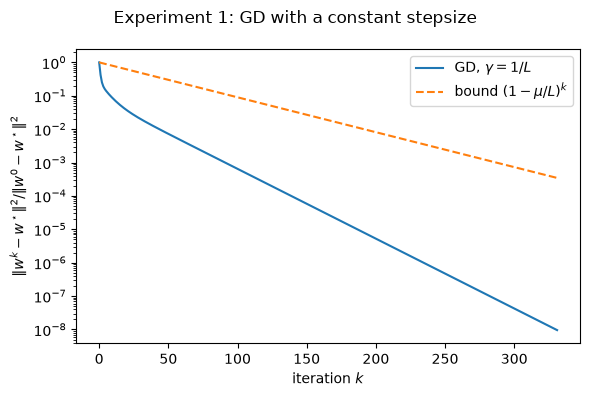

GD 1/L: 331 steps, 68.5 ms to reach ||w^k - w*||^2 <= 1e-08 ||w^0 - w*||^2 (theory: 774 steps); bound violated: False
Step count and time:
  GD, 1/L                   44 steps,    726528 grads,     8.0 ms


In [9]:
gd_const = gd(gd_constant(1 / L))
k = np.arange(len(gd_const["err"]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(k, gd_const["err"] / R0, label=r"GD, $\gamma = 1/L$")
ax.semilogy(k, (1 - mu / L) ** k, "--", label=r"bound $(1-\mu/L)^k$")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|w^k-w^\star\|^2 / \|w^0-w^\star\|^2$")
ax.legend()
fig.suptitle("Experiment 1: GD with a constant stepsize")
save(fig, "lin_exp1_gd.png")

print(f"GD 1/L: {len(k) - 1} steps, {1e3 * gd_const['time'][-1]:.1f} ms to reach "
      f"||w^k - w*||^2 <= {TOL:g} ||w^0 - w*||^2 (theory: {np.log(1 / TOL) / (mu / L):.0f} steps); "
      f"bound violated: {np.any(gd_const['err'] / R0 > (1 - mu / L) ** k * (1 + 1e-9))}")
print("Step count and time:")
measure("GD, 1/L", gd_step(gd_constant(1 / L)), stochastic=False, max_steps=5000)

## Experiment 2: GD with the Polyak stepsize
Checks: $\frac{1}{L} \le \gamma_k \le \frac{1}{\mu}$, and $\|w^{k+1} - w^\star\|^2 \le (1-\gamma_k\mu)\|w^k - w^\star\|^2$ at every step.
Dashed: the bounds $(1-\frac{\mu}{L})^k\|w^0 - w^\star\|^2$ (GD, $\gamma = \frac{1}{L}$) and $\prod_{j<k}(1-\gamma_j\mu)\,\|w^0 - w^\star\|^2$ (Polyak).

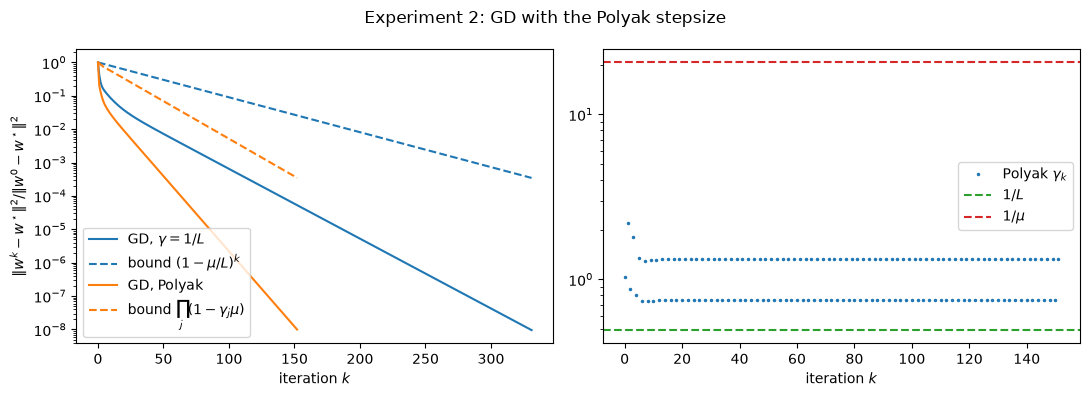

GD Polyak: 152 steps, 42.2 ms to reach the tolerance (GD 1/L: 331 steps, 68.5 ms)
gamma_k in [0.7386, 2.1957], 1/L = 0.4916, 1/mu = 20.6661; 1/L <= gamma_k <= 1/mu for all k: True
one-step bound holds for all k: True
Step count and time:
  GD, Polyak                19 steps,    313728 grads,     5.0 ms


In [10]:
gd_pol = gd(gd_polyak)
kp = np.arange(len(gd_pol["err"]))
gam = gd_pol["gamma"]
bound_pol = np.concatenate([[1.0], np.cumprod(1 - gam * mu)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.semilogy(k, gd_const["err"] / R0, color="C0", label=r"GD, $\gamma = 1/L$")
ax.semilogy(k, (1 - mu / L) ** k, "--", color="C0", label=r"bound $(1-\mu/L)^k$")
ax.semilogy(kp, gd_pol["err"] / R0, color="C1", label="GD, Polyak")
ax.semilogy(kp, bound_pol, "--", color="C1", label=r"bound $\prod_j(1-\gamma_j\mu)$")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|w^k-w^\star\|^2 / \|w^0-w^\star\|^2$")
ax.legend()
ax = axes[1]
ax.plot(gam, ".", ms=3, label=r"Polyak $\gamma_k$")
ax.axhline(1 / L, ls="--", color="C2", label=r"$1/L$")
ax.axhline(1 / mu, ls="--", color="C3", label=r"$1/\mu$")
ax.set_yscale("log")
ax.set_xlabel("iteration $k$")
ax.legend()
fig.suptitle("Experiment 2: GD with the Polyak stepsize")
save(fig, "lin_exp2_polyak.png")

step_ok = gd_pol["err"][1:] <= (1 - gam * mu) * gd_pol["err"][:-1] * (1 + 1e-9)
print(f"GD Polyak: {len(kp) - 1} steps, {1e3 * gd_pol['time'][-1]:.1f} ms to reach the tolerance "
      f"(GD 1/L: {len(k) - 1} steps, {1e3 * gd_const['time'][-1]:.1f} ms)")
print(f"gamma_k in [{gam.min():.4f}, {gam.max():.4f}], 1/L = {1 / L:.4f}, 1/mu = {1 / mu:.4f}; "
      f"1/L <= gamma_k <= 1/mu for all k: {np.all((gam >= 1 / L * (1 - 1e-9)) & (gam <= 1 / mu * (1 + 1e-9)))}")
print(f"one-step bound holds for all k: {np.all(step_ok)}")
print("Step count and time:")
measure("GD, Polyak", gd_step(gd_polyak), stochastic=False, max_steps=5000)

In [11]:
# ---- TEMP: trace of GD with the Polyak stepsize ----
K = 10                    # number of iterations to run
SHOW = range(0, K)        # which iterations to print, e.g. K = 106, SHOW = list(range(10)) + list(range(100, 106))

np.set_printoptions(precision=4, suppress=True, linewidth=150, sign='+')
H = X_train.T @ X_train / N
lam, V = np.linalg.eigh(H)            # lam[0] = mu, lam[-1] = L
print(f"mu = {mu:.4f}, L = {L:.4f}, f* = {f_star:.6f}")
print("x* =", w_star, "\n")

w = W0.copy()
for k in range(K):
    g = grad_f(X_train, y_train, w)
    fk = f(X_train, y_train, w)
    gamma = gd_polyak(w, g)
    e = w - w_star
    a = V.T @ e                       # error in the eigenbasis of H
    if k in SHOW:
        print(f"--- k = {k} ---")
        print(f"x_k         = {w}")
        print(f"grad f(x_k) = {g}")
        print(f"f(x_k)-f* = {fk - f_star:.6e}   ||grad||^2 = {g @ g:.6e}   ||x_k-x*||^2 = {e @ e:.6e}")
        print(f"gamma_k     = {gamma:.6f}   (1/L = {1/L:.4f}, 1/mu = {1/mu:.4f})")
        print(f"error along mu-dir = {a[0]:+.4e},  along L-dir = {a[-1]:+.4e}\n")
    w = w - gamma * g
np.set_printoptions()                 # restore default printing

mu = 0.0484, L = 2.0343, f* = 0.208672
x* = [+0.9601 +0.1597 -0.2149 +0.2652 +0.0427 -0.2919 -0.799  -0.7385 +2.0878] 

--- k = 0 ---
x_k         = [+0. +0. +0. +0. +0. +0. +0. +0. +0.]
grad f(x_k) = [-0.708  -0.1252 -0.2646 +0.1682 -0.0035 +0.3172 +0.1659 +0.0539 -2.0651]
f(x_k)-f* = 2.587442e+00   ||grad||^2 = 5.010915e+00   ||x_k-x*||^2 = 6.693756e+00
gamma_k     = 1.032723   (1/L = 0.4916, 1/mu = 20.6661)
error along mu-dir = -7.3109e-01,  along L-dir = -1.5727e-02

--- k = 1 ---
x_k         = [+0.7312 +0.1293 +0.2733 -0.1737 +0.0036 -0.3275 -0.1713 -0.0556 +2.1327]
grad f(x_k) = [+0.0565 -0.114  +0.2564 -0.0333 -0.0588 +0.0161 +0.0651 +0.0589 +0.0626]
f(x_k)-f* = 1.079958e-01   ||grad||^2 = 9.836986e-02   ||x_k-x*||^2 = 1.349537e+00
gamma_k     = 2.195710   (1/L = 0.4916, 1/mu = 20.6661)
error along mu-dir = -6.9456e-01,  along L-dir = +1.7314e-02

--- k = 2 ---
x_k         = [+0.6071 +0.3796 -0.2896 -0.1006 +0.1327 -0.3628 -0.3143 -0.185  +1.9953]
grad f(x_k) = [-0.3683 +0.2383 -

=== x0 = [9.0, 1.5] (general start) ===
k=0: x_k = (+9.0000, +1.5000)   gamma_k = 0.3382   (1 - gamma*mu, 1 - gamma*L) = (+0.662, -2.382)
k=1: x_k = (+5.9559, -3.5735)   gamma_k = 0.1243   (1 - gamma*mu, 1 - gamma*L) = (+0.876, -0.243)
k=2: x_k = (+5.2154, +0.8692)   gamma_k = 0.3382   (1 - gamma*mu, 1 - gamma*L) = (+0.662, -2.382)
k=3: x_k = (+3.4514, -2.0708)   gamma_k = 0.1243   (1 - gamma*mu, 1 - gamma*L) = (+0.876, -0.243)
k=4: x_k = (+3.0223, +0.5037)   gamma_k = 0.3382   (1 - gamma*mu, 1 - gamma*L) = (+0.662, -2.382)
k=5: x_k = (+2.0000, -1.2000)   gamma_k = 0.1243   (1 - gamma*mu, 1 - gamma*L) = (+0.876, -0.243)
1/gamma_a + 1/gamma_b = 11.0000,  mu + L = 11.0

=== x0 = [9.0, 0.0] (on the $\mu$-axis ($x_2 = x_2^\star$)) ===
k=0: x_k = (+9.0000, +0.0000)   gamma_k = 1.0000   (1 - gamma*mu, 1 - gamma*L) = (+0.000, -9.000)
stopped after 1 step(s): x_1 = [+0. +0.]

=== x0 = [0.0, 3.0] (on the $L$-axis ($x_1 = x_1^\star$)) ===
k=0: x_k = (+0.0000, +3.0000)   gamma_k = 0.1000   (1 - g

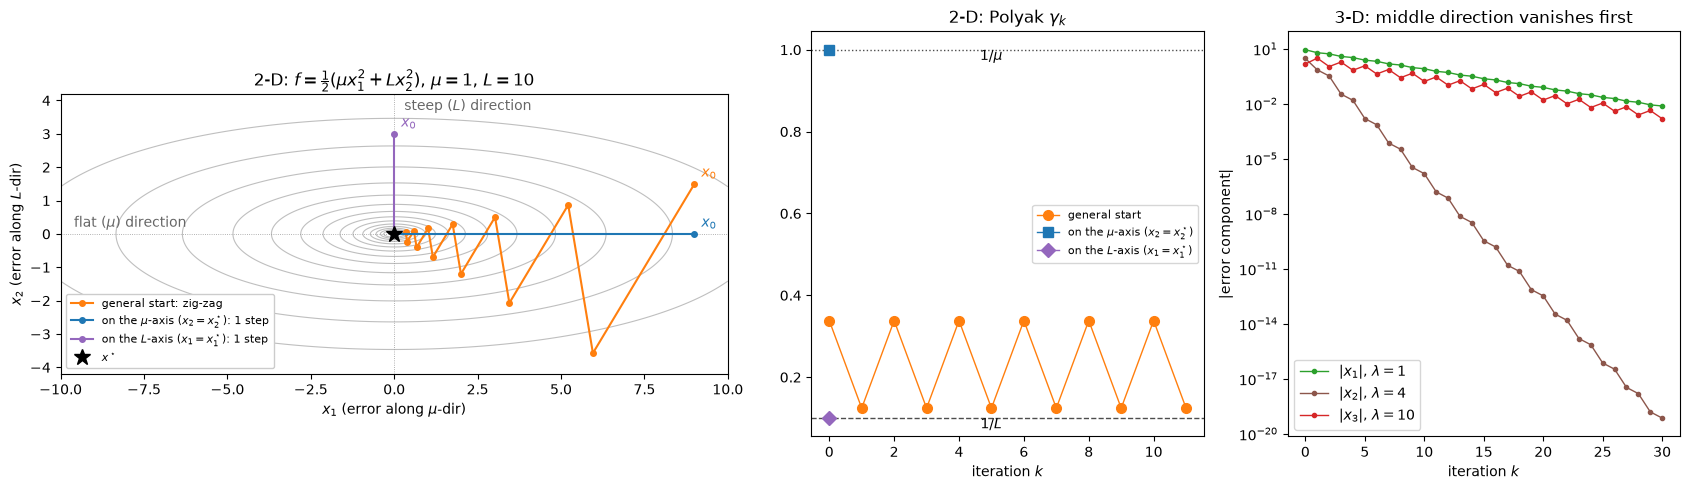

In [20]:
# ---- TEMP: toy example, Polyak stepsize on a 2-D / 3-D quadratic ----
# f(x) = 1/2 (a_1 x_1^2 + a_2 x_2^2 [+ a_3 x_3^2]), minimum x* = 0, f* = 0.
# a_1 small = flat direction, a_2 large = steep direction.
def polyak_toy(lams, x0, iters):
    lams = np.asarray(lams, float)
    x, xs, gs = np.asarray(x0, float), [], []
    for _ in range(iters):
        xs.append(x)
        g = lams * x                                  # grad f = (a_i x_i)_i
        if not np.any(g):                             # reached x* exactly: gamma would be 0/0
            break
        gamma = 2 * (0.5 * np.sum(lams * x ** 2)) / np.sum(g ** 2)
        gs.append(gamma)
        x = x - gamma * g
    xs.append(x)
    return np.array(xs), np.array(gs)

a1, a2 = 1.0, 10.0
# starting points: (label, x0, color). x* = (0, 0), so x0 IS the initial error.
STARTS = [
    ("general start", [9.0, 1.5], "C1"),
    (r"on the $x_1$-axis ($x_2 = x_2^\star$)", [9.0, 0.0], "C0"),
    (r"on the $x_2$-axis ($x_1 = x_1^\star$)", [0.0, 3.0], "C4"),
]
runs = []
for label, x0, color in STARTS:
    xs, gs = polyak_toy([a1, a2], x0=x0, iters=12)
    runs.append((label, xs, gs, color))
    print(f"=== x0 = {x0} ({label}) ===")
    for k in range(min(6, len(gs))):
        print(f"k={k}: x_k = ({xs[k, 0]:+.4f}, {xs[k, 1]:+.4f})   gamma_k = {gs[k]:.4f}   "
              f"(1 - gamma*a1, 1 - gamma*a2) = ({1 - gs[k] * a1:+.3f}, {1 - gs[k] * a2:+.3f})")
    if len(gs) >= 2:
        print(f"1/gamma_a + 1/gamma_b = {1 / gs[-1] + 1 / gs[-2]:.4f},  a1 + a2 = {a1 + a2}\n")
    else:
        print(f"stopped after {len(gs)} step(s): x_{len(gs)} = {xs[-1]}\n")

fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw=dict(width_ratios=[1.7, 1, 1]))

# (1) level sets f = const are ellipses; the general path zig-zags, the on-axis paths jump straight to x*
u, v = np.meshgrid(np.linspace(-10, 10, 400), np.linspace(-4.2, 4.2, 300))
ax[0].contour(u, v, 0.5 * (a1 * u ** 2 + a2 * v ** 2), levels=np.geomspace(0.05, 60, 14),
              colors="0.75", linewidths=0.8)
ax[0].axhline(0, color="0.6", lw=0.6, ls=":")
ax[0].axvline(0, color="0.6", lw=0.6, ls=":")
for label, xs, gs, color in runs:
    ax[0].plot(xs[:, 0], xs[:, 1], "-o", color=color, ms=4, lw=1.5, label=f"{label}: " + ("zig-zag" if len(gs) > 1 else "1 step"))
    ax[0].annotate("$x_0$", xs[0], textcoords="offset points", xytext=(5, 5), color=color)
ax[0].plot(0, 0, "k*", ms=12, label=r"$x^\star$")
ax[0].text(-9.6, 0.2, r"flat direction", color="0.4")
ax[0].text(0.3, 3.7, r"steep direction", color="0.4")
ax[0].set_aspect("equal")
ax[0].set_title(rf"2-D: $f=\frac{{1}}{{2}}(a_1 x_1^2 + a_2 x_2^2)$, $a_1={a1:g}$, $a_2={a2:g}$")
ax[0].set_xlabel(r"$x_1$")
ax[0].set_ylabel(r"$x_2$")
ax[0].legend(loc="lower left", framealpha=1, fontsize=8)

# (2) general start: gamma_k ping-pongs; on-axis starts: a single step with gamma = 1/a1 or 1/a2
ax[1].axhline(1 / a2, color="0.3", ls="--", lw=1)
ax[1].axhline(1 / a1, color="0.3", ls=":", lw=1)
ax[1].text(5, 1 / a2, r"$1/a_2$", va="top", ha="center")
ax[1].text(5, 1 / a1, r"$1/a_1$", va="top", ha="center")
for (label, xs, gs, color), mk in zip(runs, ["o", "s", "D"]):
    ax[1].plot(gs, mk + "-", color=color, ms=7, lw=1, label=label)
ax[1].set_title(r"2-D: Polyak $\gamma_k$")
ax[1].set_xlabel("iteration $k$")
ax[1].legend(fontsize=8, loc="center right")

# (3) 3-D: a middle eigenvalue dies out fastest, leaving the 2-D zig-zag
a3s = [1.0, 4.0, 10.0]              # a_1, a_2, a_3
xs3, _ = polyak_toy(a3s, x0=[9.0, 3.0, 1.5], iters=30)
for j, (a_j, c_j) in enumerate(zip(a3s, ["C2", "C5", "C3"])):
    ax[2].semilogy(np.abs(xs3[:, j]), "o-", ms=3, lw=1, color=c_j, label=rf"$|x_{j + 1}|$, $a_{j + 1}={a_j:g}$")
ax[2].set_title(r"3-D: middle direction vanishes first")
ax[2].set_xlabel("iteration $k$")
ax[2].set_ylabel("|error component|")
ax[2].legend()

save(fig, "lin_exp2_polyak_toy.png")

## Experiment 3: SGD with the AC constants
Theorem 33 with $A = 2L_{\max}$, $C = 2\sigma_\star^2$ (Exercise 29): for $0 < \gamma \le \frac{1}{A}$,
$\ \mathbb{E}\|w^k - w^\star\|^2 \le (1-\gamma\mu)^k\|w^0 - w^\star\|^2 + \frac{\gamma C}{\mu}$.

**3a.** $\gamma = \frac{1}{A}$ and the bound. **3b.** $\gamma = \frac{1}{mA}$, $m = 1, 2, 4$: the neighbourhood
is proportional to $\gamma$. **3c.** $\gamma = \frac{m}{A}$, $m = 1, 2, 4, 8, 16$: stepsizes larger than the theory allows.

3a: gamma = 1/A = 0.0110: plateau 0.0291, radius gamma C / mu = 1.8131, bound violated: False
3b: gamma = 1/(1A): plateau 0.0291, radius 1.8131, plateau * m = 0.0291, bound violated: False
3b: gamma = 1/(2A): plateau 0.0141, radius 0.9066, plateau * m = 0.0283, bound violated: False
3b: gamma = 1/(4A): plateau 0.0070, radius 0.4533, plateau * m = 0.0279, bound violated: False
3c: gamma = 1/A = 0.0110: plateau 0.0291, reaches 1.1 x plateau after 4380 steps
3c: gamma = 2/A = 0.0221: plateau 0.0621, reaches 1.1 x plateau after 2073 steps
3c: gamma = 4/A = 0.0441: plateau 0.1435, reaches 1.1 x plateau after 734 steps
3c: gamma = 8/A = 0.0882: plateau 0.4299, reaches 1.1 x plateau after 220 steps
3c: gamma = 16/A = 0.1765: does not converge (E||w^k - w*||^2 ends at 49.1 > ||w^0 - w*||^2 = 6.69)


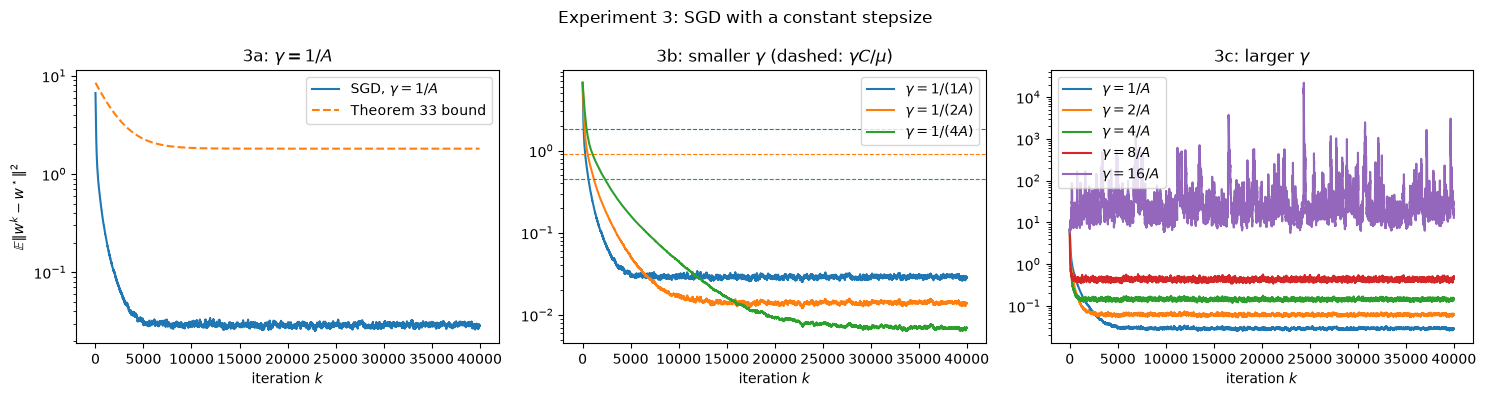

Step count and time (single runs, mean over seeds; at most 60000 steps):
  SGD-US, 1/(4A)          7869 steps,      7869 grads,    62.5 ms
  SGD-US, 1/(2A)          4125 steps,      4125 grads,    32.5 ms
  SGD-US, 1/A             2041 steps,      2041 grads,    17.0 ms
  SGD-US, 2/A             1041 steps,      1041 grads,     8.0 ms
  SGD-US, 4/A              669 steps,       669 grads,     5.4 ms


In [19]:
ITERS = 40000
k3 = np.arange(ITERS + 1)

def bound33(gamma, k):
    return (1 - gamma * mu) ** k * R0 + gamma * C / mu

sgd_runs = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# 3a
gamma = 1 / A
run = sgd_runs[1.0] = sgd(sgd_constant(gamma), ITERS)
ax = axes[0]
ax.semilogy(run["err"], label=r"SGD, $\gamma = 1/A$")
ax.semilogy(bound33(gamma, k3), "--", label="Theorem 33 bound")
ax.set_title(r"3a: $\gamma = 1/A$")
print(f"3a: gamma = 1/A = {gamma:.4f}: plateau {run['err'][-5000:].mean():.4f}, "
      f"radius gamma C / mu = {gamma * C / mu:.4f}, bound violated: {np.any(run['err'] > bound33(gamma, k3))}")
# 3b
ax = axes[1]
for m in [1, 2, 4]:
    gamma = 1 / (m * A)
    run = sgd_runs[1 / m] = sgd_runs.get(1 / m) or sgd(sgd_constant(gamma), ITERS)
    line, = ax.semilogy(run["err"], label=fr"$\gamma = 1/({m}A)$")
    ax.axhline(gamma * C / mu, ls="--", color=line.get_color(), lw=0.8)
    plateau = run["err"][-5000:].mean()
    print(f"3b: gamma = 1/({m}A): plateau {plateau:.4f}, radius {gamma * C / mu:.4f}, "
          f"plateau * m = {plateau * m:.4f}, bound violated: {np.any(run['err'] > bound33(gamma, k3))}")
ax.set_title(r"3b: smaller $\gamma$ (dashed: $\gamma C/\mu$)")
# 3c
ax = axes[2]
for m in [1, 2, 4, 8, 16]:
    gamma = m / A
    run = sgd_runs[m] = sgd_runs.get(m) or sgd(sgd_constant(gamma), ITERS)
    err = run["err"]
    ax.semilogy(np.where(np.isfinite(err), err, np.nan), label=fr"$\gamma = {m}/A$")
    plateau = err[-5000:].mean()
    if np.isfinite(plateau) and plateau < R0:
        hit = np.argmax(err <= 1.1 * plateau)
        print(f"3c: gamma = {m}/A = {gamma:.4f}: plateau {plateau:.4f}, "
              f"reaches 1.1 x plateau after {hit} steps")
    else:
        print(f"3c: gamma = {m}/A = {gamma:.4f}: does not converge "
              f"(E||w^k - w*||^2 ends at {plateau:.3g} > ||w^0 - w*||^2 = {R0:.3g})")
ax.set_title(r"3c: larger $\gamma$")
for ax in axes:
    ax.set_xlabel("iteration $k$")
    ax.legend()
axes[0].set_ylabel(r"$\mathbb{E}\|w^k-w^\star\|^2$")
fig.suptitle("Experiment 3: SGD with a constant stepsize")
save(fig, "lin_exp3_sgd.png")

print("Step count and time (single runs, mean over seeds; at most 60000 steps):")
for label, gamma in [("1/(4A)", 1 / (4 * A)), ("1/(2A)", 1 / (2 * A)), ("1/A", 1 / A),
                     ("2/A", 2 / A), ("4/A", 4 / A)]:
    measure(f"SGD-US, {label}", sgd_step(gamma), stochastic=True, max_steps=60000)

## Experiment 4: SGD with importance sampling (SGD-IS)
$p_i = \frac{L_i}{\sum_j L_j}$ and the step $\gamma\frac{\nabla f_i(w^k)}{np_i}$. Theorem 38: with $A'' = \max_i\frac{L_i}{np_i} = \bar L$,
$A_{\rm IS} = 2A'' = 2\bar L$, $\sigma_{\star,{\rm IS}}^2 = \frac{1}{n^2}\sum_i\frac{\|\nabla f_i(w^\star)\|^2}{p_i}$ and $C_{\rm IS} = 2\sigma_{\star,{\rm IS}}^2$,
for $0 < \gamma \le \frac{1}{A_{\rm IS}}$:
$\ \mathbb{E}\|w^k - w^\star\|^2 \le (1-\gamma\mu)^k\|w^0 - w^\star\|^2 + \frac{\gamma C_{\rm IS}}{\mu}$.

**4a.** $\gamma = \frac{1}{A_{\rm IS}}$ and the bound. **4b.** $\gamma = \frac{1}{mA_{\rm IS}}$, $m = 1, 2, 4$: the neighbourhood
is proportional to $\gamma$. **4c.** $\gamma = \frac{m}{A_{\rm IS}}$, $m = 1, 2, 3, 4$: stepsizes larger than the theory allows.
With IS every step moves along $x_i$ by the same factor $1 - \gamma\frac{L_i}{np_i} = 1 - \gamma\bar L$, so all steps overshoot at once when $\gamma\bar L > 2$, i.e. $m > 4$.

SGD-US: A    = 2 L_max =  90.66, gamma = 1/A    = 0.0110, C    = 7.954, radius gamma C / mu = 1.813
SGD-IS: A_IS = 2 L_bar =  15.77, gamma = 1/A_IS = 0.0634, C_IS = 6.583, radius gamma C / mu = 8.625
4a: gamma = 1/A_IS = 0.0634: plateau 0.1686, radius gamma C_IS / mu = 8.6249, bound violated: False
4b: gamma = 1/(1A_IS): plateau 0.1686, radius 8.6249, plateau * m = 0.1686, bound violated: False
4b: gamma = 1/(2A_IS): plateau 0.0728, radius 4.3124, plateau * m = 0.1457, bound violated: False
4b: gamma = 1/(4A_IS): plateau 0.0341, radius 2.1562, plateau * m = 0.1363, bound violated: False
4c: gamma = 1/A_IS = 0.0634: plateau 0.1686, reaches 1.1 x plateau after 490 steps
4c: gamma = 2/A_IS = 0.1268: plateau 0.4975, reaches 1.1 x plateau after 144 steps
4c: gamma = 3/A_IS = 0.1902: plateau 1.4634, reaches 1.1 x plateau after 86 steps
4c: gamma = 4/A_IS = 0.2536: does not converge (E||w^k - w*||^2 ends at 7.99e+03 > ||w^0 - w*||^2 = 6.69)


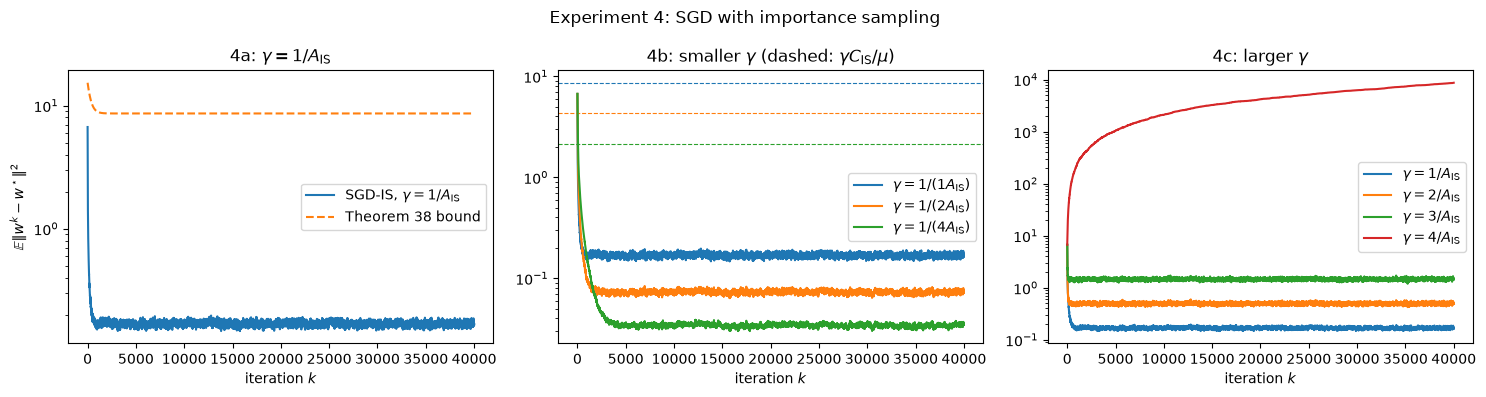

Step count and time (single runs, mean over seeds; at most 60000 steps):
  SGD-IS, 1/(4A_IS)       1511 steps,      1511 grads,    15.2 ms
  SGD-IS, 1/(2A_IS)        910 steps,       910 grads,     8.3 ms
  SGD-IS, 1/A_IS           412 steps,       412 grads,     3.4 ms
  SGD-IS, 2/A_IS           829 steps,       829 grads,     8.1 ms


In [13]:
# importance sampling: p_i = L_i / sum_j L_j
p_is = c["L_i"] / c["L_i"].sum()
A_IS = 2 * np.max(c["L_i"] / (N * p_is))                                 # 2 A'' = 2 L_bar
G_star = grad_f_i(X_train, y_train, np.arange(N), w_star)               # rows: grad f_i(w*)
sigma2_is = np.sum(np.sum(G_star ** 2, axis=1) / p_is) / N ** 2         # (grad f(w*) = 0)
C_IS = 2 * sigma2_is
print(f"SGD-US: A    = 2 L_max = {A:6.2f}, gamma = 1/A    = {1 / A:.4f}, C    = {C:.3f}, "
      f"radius gamma C / mu = {C / (A * mu):.3f}")
print(f"SGD-IS: A_IS = 2 L_bar = {A_IS:6.2f}, gamma = 1/A_IS = {1 / A_IS:.4f}, C_IS = {C_IS:.3f}, "
      f"radius gamma C / mu = {C_IS / (A_IS * mu):.3f}")


def bound38(gamma, k):
    return (1 - gamma * mu) ** k * R0 + gamma * C_IS / mu


is_runs = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# 4a
gamma = 1 / A_IS
run = is_runs[1.0] = sgd(sgd_constant(gamma), ITERS, p=p_is)
ax = axes[0]
ax.semilogy(run["err"], label=r"SGD-IS, $\gamma = 1/A_{\rm IS}$")
ax.semilogy(bound38(gamma, k3), "--", label="Theorem 38 bound")
ax.set_title(r"4a: $\gamma = 1/A_{\rm IS}$")
print(f"4a: gamma = 1/A_IS = {gamma:.4f}: plateau {run['err'][-5000:].mean():.4f}, "
      f"radius gamma C_IS / mu = {gamma * C_IS / mu:.4f}, bound violated: {np.any(run['err'] > bound38(gamma, k3))}")
# 4b
ax = axes[1]
for m in [1, 2, 4]:
    gamma = 1 / (m * A_IS)
    run = is_runs[1 / m] = is_runs.get(1 / m) or sgd(sgd_constant(gamma), ITERS, p=p_is)
    line, = ax.semilogy(run["err"], label=fr"$\gamma = 1/({m}A_{{\rm IS}})$")
    ax.axhline(gamma * C_IS / mu, ls="--", color=line.get_color(), lw=0.8)
    plateau = run["err"][-5000:].mean()
    print(f"4b: gamma = 1/({m}A_IS): plateau {plateau:.4f}, radius {gamma * C_IS / mu:.4f}, "
          f"plateau * m = {plateau * m:.4f}, bound violated: {np.any(run['err'] > bound38(gamma, k3))}")
ax.set_title(r"4b: smaller $\gamma$ (dashed: $\gamma C_{\rm IS}/\mu$)")
# 4c
ax = axes[2]
for m in [1, 2, 3, 4]:
    gamma = m / A_IS
    run = is_runs[m] = is_runs.get(m) or sgd(sgd_constant(gamma), ITERS, p=p_is)
    err = run["err"]
    ax.semilogy(np.where(np.isfinite(err), err, np.nan), label=fr"$\gamma = {m}/A_{{\rm IS}}$")
    plateau = err[-5000:].mean()
    if np.isfinite(plateau) and plateau < R0:
        hit = np.argmax(err <= 1.1 * plateau)
        print(f"4c: gamma = {m}/A_IS = {gamma:.4f}: plateau {plateau:.4f}, "
              f"reaches 1.1 x plateau after {hit} steps")
    else:
        print(f"4c: gamma = {m}/A_IS = {gamma:.4f}: does not converge "
              f"(E||w^k - w*||^2 ends at {plateau:.3g} > ||w^0 - w*||^2 = {R0:.3g})")
ax.set_title(r"4c: larger $\gamma$")
for ax in axes:
    ax.set_xlabel("iteration $k$")
    ax.legend()
axes[0].set_ylabel(r"$\mathbb{E}\|w^k-w^\star\|^2$")
fig.suptitle("Experiment 4: SGD with importance sampling")
save(fig, "lin_exp4_sgd_is.png")

print("Step count and time (single runs, mean over seeds; at most 60000 steps):")
for label, gamma in [("1/(4A_IS)", 1 / (4 * A_IS)), ("1/(2A_IS)", 1 / (2 * A_IS)), ("1/A_IS", 1 / A_IS),
                     ("2/A_IS", 2 / A_IS)]:
    measure(f"SGD-IS, {label}", sgd_step(gamma, p_is), stochastic=True, max_steps=60000)


## Experiment 5: comparison
We compare GD with $\gamma = \frac{1}{L}$, GD with the Polyak stepsize, SGD-US with $\gamma = \frac{1}{A}$ and SGD-IS with
$\gamma = \frac{1}{A_{\rm IS}} = \frac{1}{2\bar L}$ (Theorem 38), all from $w^0 = 0$.
* left: the error against the **iteration** $k$ (linear axis up to $k = 1$, logarithmic after), so all curves start at $k = 0$;
* right: the error against the measured **wall-clock time** (only the update steps are timed).

GD curves are single (deterministic) runs. The SGD errors are means over $50$ runs; its time axis is the
measured time per step of single runs (mean over $5$ seeds). The table collects the step counts and times of all experiments.

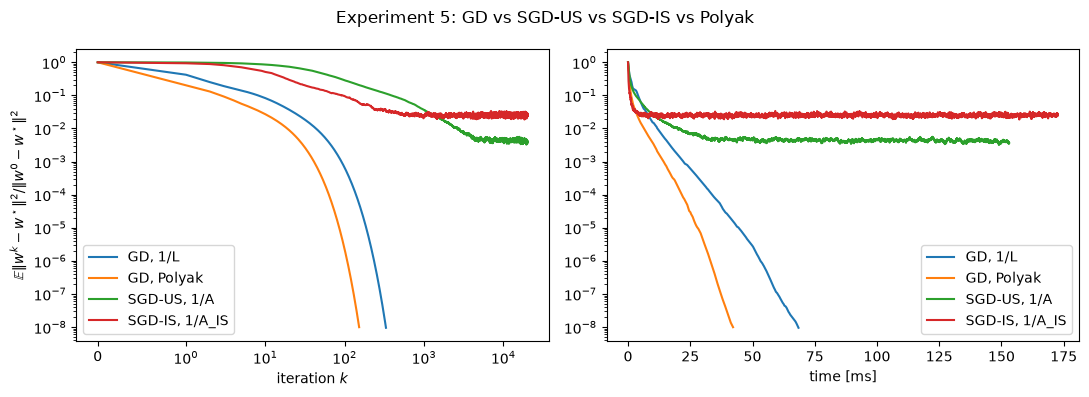

Steps, gradient evaluations and time until ||w^k - w*||^2 <= 0.01 ||w^0 - w*||^2:

method             |                                             | time / step
--------------------------------------------------------------------------------
GD, 1/L            |       44 steps,    726528 grads,     8.0 ms |    180.7 us
GD, Polyak         |       19 steps,    313728 grads,     5.0 ms |    262.8 us
SGD-US, 1/(4A)     |     7869 steps,      7869 grads,    59.7 ms |      7.6 us
SGD-US, 1/(2A)     |     4125 steps,      4125 grads,    32.5 ms |      7.9 us
SGD-US, 1/A        |     2041 steps,      2041 grads,    19.0 ms |      9.3 us
SGD-US, 2/A        |     1041 steps,      1041 grads,     9.8 ms |      9.4 us
SGD-US, 4/A        |      669 steps,       669 grads,     6.7 ms |     10.0 us
SGD-IS, 1/(4A_IS)  |     1511 steps,      1511 grads,    15.2 ms |     10.1 us
SGD-IS, 1/(2A_IS)  |      910 steps,       910 grads,     8.3 ms |      9.1 us
SGD-IS, 1/A_IS     |      412 steps,       412

In [14]:
SGD_STEPS = 20000
RUNS4 = 50


def step_times(step, steps, seeds=SEEDS):
    # cumulative time of `steps` update steps (single runs), mean over seeds; t[0] = 0
    T = np.zeros((seeds, steps + 1))
    for s in range(seeds):
        rng = np.random.default_rng(SEED + 100 + s)
        w = W0.copy()
        for k in range(steps):
            t0 = time.perf_counter()
            w = step(w, rng)
            T[s, k + 1] = T[s, k] + time.perf_counter() - t0
    return T.mean(axis=0)


sgd_run = sgd(sgd_constant(1 / A), SGD_STEPS, runs=RUNS4)
t_sgd = step_times(sgd_step(1 / A), SGD_STEPS)
sgd_is_run = sgd(sgd_constant(1 / A_IS), SGD_STEPS, runs=RUNS4, p=p_is)
t_sgd_is = step_times(sgd_step(1 / A_IS, p_is), SGD_STEPS)
curves = {   # name -> (error at k = 0, 1, ..., time at each k)
    "GD, 1/L": (gd_const["err"], np.concatenate([[0.0], gd_const["time"]])),
    "GD, Polyak": (gd_pol["err"], np.concatenate([[0.0], gd_pol["time"]])),
    "SGD-US, 1/A": (sgd_run["err"], t_sgd),
    "SGD-IS, 1/A_IS": (sgd_is_run["err"], t_sgd_is),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (err, t) in curves.items():
    axes[0].semilogy(np.arange(len(err)), err / R0, label=name)
    axes[1].semilogy(1e3 * t[:len(err)], err / R0, label=name)
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xlabel("iteration $k$")
axes[1].set_xlabel("time [ms]")
axes[0].set_ylabel(r"$\mathbb{E}\|w^k-w^\star\|^2 / \|w^0-w^\star\|^2$")
for ax in axes:
    ax.legend()
fig.suptitle("Experiment 5: GD vs SGD-US vs SGD-IS vs Polyak")
save(fig, "lin_exp5_comparison.png")

print(f"Steps, gradient evaluations and time until ||w^k - w*||^2 <= {TOL_ERR:g} ||w^0 - w*||^2:\n")
print(f"{'method':18s} | {'':^43s} | {'time / step':>11s}")
print("-" * 80)
for name, res in RESULTS.items():
    per_step = f"{1e6 * res[2] / res[0]:8.1f} us" if res else ""
    print(f"{name:18s} | {fmt(res)} | {per_step:>11s}")